# Projeto Final - Processamento de Imagens
**Nomes:** Laura Medeiros Dal Ponte e Mariana Melo Pereira

## Introdução

## Importação das bibiotecas e configuração inicial

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from PIL import Image, ImageFile
from tqdm.auto import tqdm
import hashlib
from sklearn.model_selection import train_test_split

/home/mariana25021/miniconda3/envs/teste_deepinv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42

## Experimento 1: Divisão convencional

### Criando diretórios

In [3]:
ImageFile.LOAD_TRUNCATED_IMAGES = False

PROJECT_DIR = Path("..").resolve()

DATA_DIR = PROJECT_DIR / "notebooks" / "DeepSafe" / "images"
OUTPUT_DIR = PROJECT_DIR / "notebooks"/ "data" / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"
}

### Construção do inventário
Percorremos as pastas e registramos: caminho do arquivo; classe; fonte ou gerador; dimensões; formato; número de canais; tamanho do arquivo.

In [4]:
def inspect_image(path):
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            width, height = img.size
            image_format = img.format
            channels = len(img.getbands())

        return {
            "valid": True,
            "width": width,
            "height": height,
            "format": image_format,
            "channels": channels,
            "file_size": path.stat().st_size
        }

    except Exception:
        return {
            "valid": False,
            "width": None,
            "height": None,
            "format": None,
            "channels": None,
            "file_size": None
        }

### Organizando em um DataFrame

In [5]:
records = []

for class_name in ["real", "fake"]:

    class_dir = DATA_DIR / class_name

    for source_dir in sorted(class_dir.iterdir()):

        if not source_dir.is_dir():
            continue

        source = source_dir.name

        image_paths = [
            p for p in source_dir.rglob("*")
            if p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        for path in tqdm(image_paths, desc=f"{class_name}/{source}"):

            info = inspect_image(path)

            records.append({
                "image_path": str(path.resolve()),
                "class": class_name,
                "label": 0 if class_name == "real" else 1,
                "source": source,
                **info
            })

df = pd.DataFrame(records)

df.to_csv(
    OUTPUT_DIR / "image_inventory.csv",
    index=False
)

print(df.shape)
print(df.groupby(["class", "source"]).size())

real/coco:   0%|          | 0/1000 [00:00<?, ?it/s]

real/coco:   0%|          | 2/1000 [00:00<01:06, 14.95it/s]

real/coco:   1%|          | 7/1000 [00:00<00:31, 31.89it/s]

real/coco:   1%|          | 11/1000 [00:00<00:29, 33.33it/s]

real/coco:   2%|▏         | 15/1000 [00:00<00:28, 34.31it/s]

real/coco:   2%|▏         | 19/1000 [00:00<00:31, 30.82it/s]

... (676 outputs left out)

fake/stable_diffusion_xl:  83%|████████▎ | 52/63 [00:01<00:00, 54.71it/s]

fake/stable_diffusion_xl:  94%|█████████▎| 59/63 [00:01<00:00, 55.47it/s]

fake/stable_diffusion_xl: 100%|██████████| 63/63 [00:01<00:00, 46.01it/s]

(4000, 10)
class  source              
fake   aurora_20_1_25            64
       chroma                    64
       dalle_2                   64
       dalle_3                   63
       firefly                   63
       flux_1                    63
       frames_23_1_25            63
       glide                     63
       gpt_image_1               63
       grok_2_image_1212         63
       halfmoon_4_4_25           44
       hidream_i1_full           63
       ideogram_2.0              63
       ideogram_3.0              63
       imagen_3.0_002            63
       imagen_4.0                63
       lumina_17_2_25            63
       midjourney_6              63
       midjourney_7              63
       midjourney_v5             63
       mystic                    63
       recraft_v2                63
       recraft_v3                63
       sd_1.5                    63
       sd_1.5_dreamshaper        63
       sd_1.5_epicdream          63
       sd_2.1            

### Removendo imagens inválidas

In [6]:
df_valid = df[df["valid"]].copy()

invalid_count = len(df) - len(df_valid)

print("Total:", len(df))
print("Valid:", len(df_valid))
print("Invalid:", invalid_count)

df_valid = df_valid.drop_duplicates(
    subset="image_path"
).reset_index(drop=True)

Total: 4000
Valid: 4000
Invalid: 0


### Verificando duplicatas

In [7]:
def calculate_hash(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            sha.update(chunk)

    return sha.hexdigest()

df_valid["sha256"] = [
    calculate_hash(path)
    for path in tqdm(df_valid["image_path"])
]

duplicates = df_valid[
    df_valid.duplicated("sha256", keep=False)
].sort_values("sha256")

print("Exact duplicate images:", len(duplicates))

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 3/4000 [00:00<02:13, 29.98it/s]

  0%|          | 19/4000 [00:00<00:38, 102.28it/s]

  1%|          | 42/4000 [00:00<00:25, 158.13it/s]

  1%|▏         | 58/4000 [00:01<01:21, 48.17it/s] 

  2%|▏         | 69/4000 [00:01<01:08, 56.98it/s]

... (266 outputs left out)

 99%|█████████▉| 3972/4000 [00:35<00:00, 104.28it/s]

100%|█████████▉| 3986/4000 [00:36<00:00, 112.47it/s]

100%|██████████| 4000/4000 [00:36<00:00, 110.68it/s]

Exact duplicate images: 14


In [8]:
duplicate_label_check = (
    df_valid.groupby("sha256")["label"].nunique()
)

conflicting_hashes = duplicate_label_check[
    duplicate_label_check > 1
]

print("Hashes with conflicting labels:", len(conflicting_hashes))

Hashes with conflicting labels: 0


In [9]:
df_clean = df_valid.drop_duplicates(
    subset="sha256",
    keep="first"
).copy()

df_clean = df_clean.drop(columns=["sha256"])

### Divisão entre treino e teste

In [10]:
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    stratify=df_clean["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

In [11]:
splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

for name, data in splits.items():

    print(f"\n{name.upper()}")
    print("Total:", len(data))

    print(
        data["class"].value_counts()
    )

    print(
        data["class"].value_counts(normalize=True) * 100
    )


TRAIN
Total: 2795
class
real    1400
fake    1395
Name: count, dtype: int64
class
real    50.089445
fake    49.910555
Name: proportion, dtype: float64

VALIDATION
Total: 599
class
real    300
fake    299
Name: count, dtype: int64
class
real    50.083472
fake    49.916528
Name: proportion, dtype: float64

TEST
Total: 599
class
real    300
fake    299
Name: count, dtype: int64
class
real    50.083472
fake    49.916528
Name: proportion, dtype: float64


### Verificando a distribuição das fontes

In [12]:
for name, data in splits.items():

    print(f"\n{name.upper()}")

    print(
        pd.crosstab(
            data["source"],
            data["class"]
        )
    )


TRAIN
class                 fake  real
source                          
aurora_20_1_25          52     0
chroma                  47     0
coco                     0   716
dalle_2                 45     0
dalle_3                 54     0
firefly                 40     0
flux_1                  45     0
frames_23_1_25          45     0
glide                   41     0
gpt_image_1             49     0
grok_2_image_1212       41     0
halfmoon_4_4_25         27     0
hidream_i1_full         46     0
ideogram_2.0            42     0
ideogram_3.0            46     0
imagen_3.0_002          49     0
imagen_4.0              39     0
lumina_17_2_25          40     0
midjourney_6            45     0
midjourney_7            45     0
midjourney_v5           41     0
mystic                  40     0
openfake                 0   684
recraft_v2              43     0
recraft_v3              43     0
sd_1.5                  39     0
sd_1.5_dreamshaper      52     0
sd_1.5_epicdream        43     0
sd_

## Treino da CNN

In [13]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from PIL import Image
import pandas as pd
import numpy as np

from pathlib import Path

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


### Dataset a partir dos caminhos das imagens 

In [14]:
class ImageClassificationDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

### Transformações

In [15]:
weights = models.ResNet18_Weights.DEFAULT

image_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### DataLoaders

In [16]:
BATCH_SIZE = 16

train_dataset = ImageClassificationDataset(
    train_df,
    transform=image_transform
)

val_dataset = ImageClassificationDataset(
    val_df,
    transform=image_transform
)

test_dataset = ImageClassificationDataset(
    test_df,
    transform=image_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

/home/mariana25021/miniconda3/envs/teste_deepinv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


### Construção da ResNet 18

In [17]:
model = models.resnet18(weights=weights)

num_features = model.fc.in_features

model.fc = nn.Linear(
    nn.Dropout(p=0.3),
    nn.Linear(num_features, 2)
)

model = model.to(DEVICE)

In [18]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=1e-3
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

### Treino

In [19]:
def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None

    model.train() if training else model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            if training:
                optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            predictions = outputs.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return {
        "loss": total_loss / total,
        "accuracy": correct / total
    }

In [20]:
EPOCHS = 20
PATIENCE = 5

best_val_loss = float("inf")
epochs_without_improvement = 0

history = []

MODEL_DIR = Path("../results/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_model_path = MODEL_DIR / "resnet18_best.pth"

for epoch in range(EPOCHS):

    train_metrics = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_metrics = run_epoch(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_metrics["loss"])

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_metrics["loss"],
        "val_loss": val_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_accuracy": val_metrics["accuracy"]
    })

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f}"
    )

    if val_metrics["loss"] < best_val_loss:

        best_val_loss = val_metrics["loss"]

        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            best_model_path
        )

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping.")
        break

/home/mariana25021/miniconda3/envs/teste_deepinv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 01/20 | Train Loss: 0.5222 | Val Loss: 0.3836 | Train Acc: 0.7385 | Val Acc: 0.8280


Epoch 02/20 | Train Loss: 0.1473 | Val Loss: 0.4597 | Train Acc: 0.9463 | Val Acc: 0.8230


Epoch 03/20 | Train Loss: 0.0526 | Val Loss: 0.4536 | Train Acc: 0.9871 | Val Acc: 0.8447


Epoch 04/20 | Train Loss: 0.0445 | Val Loss: 0.9626 | Train Acc: 0.9857 | Val Acc: 0.7312


Epoch 05/20 | Train Loss: 0.0237 | Val Loss: 0.4969 | Train Acc: 0.9946 | Val Acc: 0.8247


Epoch 06/20 | Train Loss: 0.0125 | Val Loss: 0.6231 | Train Acc: 0.9964 | Val Acc: 0.7880
Early stopping.


### Curvas de aprendizado

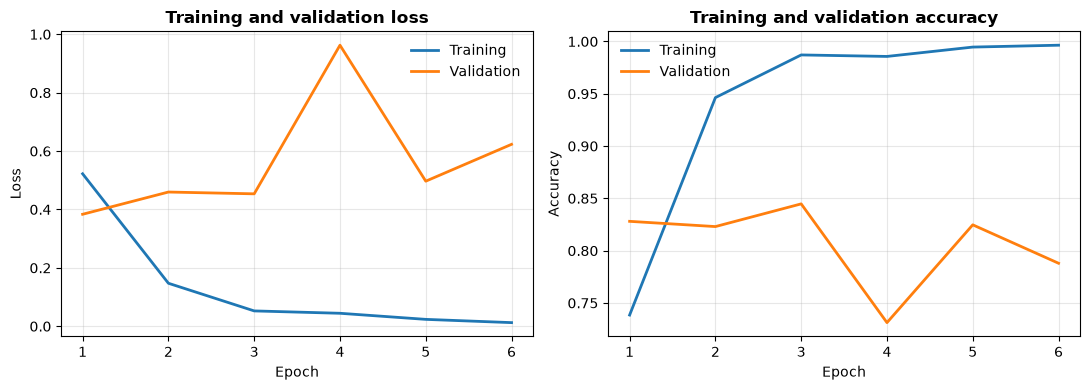

In [21]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training",
    linewidth=2
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation",
    linewidth=2
)

axes[0].set_title("Training and validation loss", weight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training",
    linewidth=2
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation",
    linewidth=2
)

axes[1].set_title("Training and validation accuracy", weight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("./results/figures/resnet_learning_curves.png", dpi=300)
plt.show()